<a href="https://colab.research.google.com/github/preethikamanokaran/HealthPredict/blob/main/Restaurant_Sales_Analysis_Using_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:

dataset = load_diabetes(as_frame=True)

X = dataset.data
y = dataset.target

print("Healthcare dataset loaded successfully!")
print("Number of records:", X.shape[0])
print("Number of features:", X.shape[1])

display(X.head())

Healthcare dataset loaded successfully!
Number of records: 442
Number of features: 10


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


Feature names:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

Statistical summary:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01



Target summary:
count    442.000000
mean     152.133484
std       77.093005
min       25.000000
25%       87.000000
50%      140.500000
75%      211.500000
max      346.000000
Name: target, dtype: float64


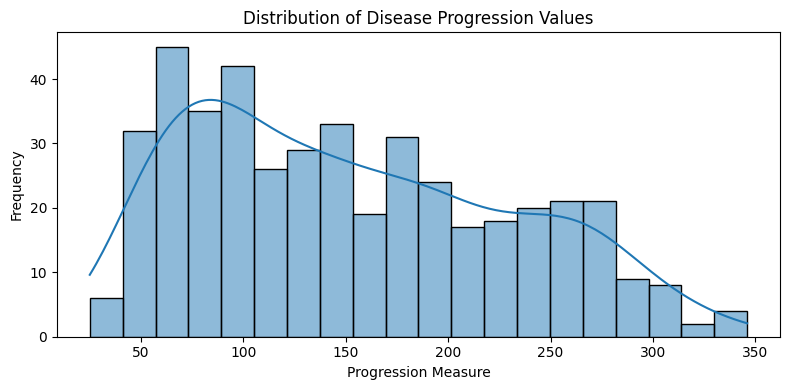

In [6]:

print("Feature names:")
print(X.columns.tolist())

print("\nStatistical summary:")
display(X.describe())

print("\nTarget summary:")
print(y.describe())

plt.figure(figsize=(8, 4))
sns.histplot(y, bins=20, kde=True)
plt.title("Distribution of Disease Progression Values")
plt.xlabel("Progression Measure")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [7]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(
    n_estimators=100, random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Model trained successfully!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Model trained successfully!
Training records: 353
Testing records: 89


In [8]:

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print("MODEL EVALUATION")
print("Mean Absolute Error:", round(mae, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R-squared Score:", round(r2, 3))

MODEL EVALUATION
Mean Absolute Error: 44.05
Root Mean Squared Error: 54.33
R-squared Score: 0.443


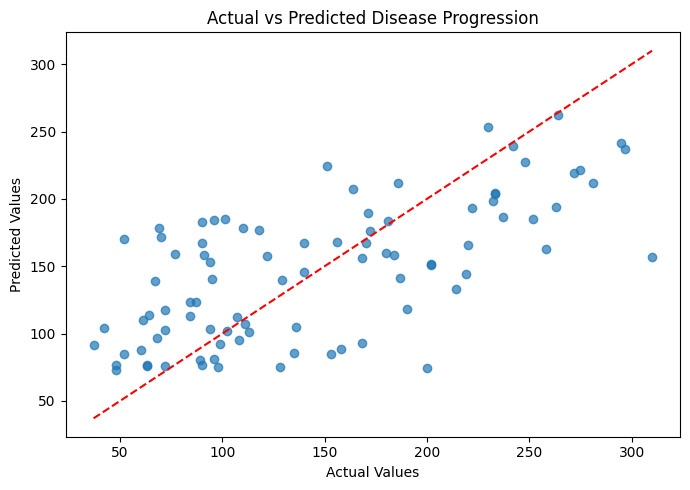

In [10]:

plt.figure(figsize=(7, 5))

plt.scatter(y_test, predictions, alpha=0.7)

lower = min(y_test.min(), predictions.min())
upper = max(y_test.max(), predictions.max())

plt.plot([lower, upper], [lower, upper], "r--")

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Disease Progression")
plt.tight_layout()
plt.show()

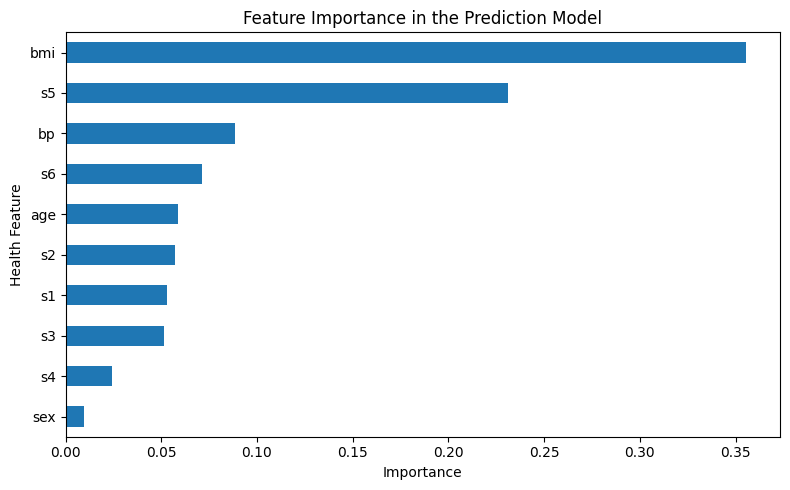

Most important feature: bmi


In [11]:

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

importance.plot(kind="barh", figsize=(8, 5))

plt.title("Feature Importance in the Prediction Model")
plt.xlabel("Importance")
plt.ylabel("Health Feature")
plt.tight_layout()
plt.show()

print("Most important feature:", importance.idxmax())

In [13]:

print("KEY FINDINGS")
print("1. The healthcare dataset was used to train a regression model.")
print("2. The model's performance was evaluated using MAE, RMSE and R-squared.")
print("3. Actual and predicted values were compared visually.")
print("4. Feature importance was analyzed to identify influential variables.")
print("5. The model's errors indicate where predictions may be improved.")

print("\nCONCLUSION")
print("A Random Forest regression model was developed using a")
print("health-related dataset. Its predictions were evaluated")
print("using standard regression metrics and visualizations.")
print("This project demonstrates applied data science and")
print("machine learning in a healthcare context.")

KEY FINDINGS
1. The healthcare dataset was used to train a regression model.
2. The model's performance was evaluated using MAE, RMSE and R-squared.
3. Actual and predicted values were compared visually.
4. Feature importance was analyzed to identify influential variables.
5. The model's errors indicate where predictions may be improved.

CONCLUSION
A Random Forest regression model was developed using a
health-related dataset. Its predictions were evaluated
using standard regression metrics and visualizations.
This project demonstrates applied data science and
machine learning in a healthcare context.


In [14]:

results.to_csv("health_prediction_results.csv", index=False)

print("Prediction results saved successfully!")

Prediction results saved successfully!


In [12]:

results = pd.DataFrame({
    "Actual Value": y_test.to_numpy(),
    "Predicted Value": predictions.round(2)
})

display(results.head(10))

,Actual Value,Predicted Value
0,219.0,144.00
1,70.0,171.58
2,202.0,150.72
3,230.0,253.71
4,111.0,107.19
5,84.0,123.54
6,242.0,239.09
7,272.0,219.01
8,94.0,153.44
9,96.0,184.59
